# RSW / 04b — Burst reversion, frozen RSW 04 rules extended to 2021-01 – 2025-12 (check)

Protocol: [`RSW 007`](../../discussions/MNQ_Regime_Switching/007_claude_rsw04_burst_reversion_preregistration.md), section 7 (extension). Same rules, engine 0.1.1, regime fits refitted before every year (2021 … 2025). Gates are reported on the original window (2021-01 – 2023-06), on the new segment (2023-07 – 2025-12) and on the whole span. This is a check of a strategy that already failed discovery: a pass on the new segment alone would not make it a candidate.


Note: June 2022 has almost no data unless it has been re-downloaded (RSW 05 coverage table).

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
SYNTH_NULL = os.environ.get("RSW_SYNTH_NULL") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import regime_ar as R
from equity_trading import hsmm as HS
from equity_trading import burst_reversion as B
from equity_trading import trail_strategy as T
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC, HC, BC = R.RSWConfig(), HS.HSMMConfig(), B.BRConfig()
D = dt.date
FULL = True
OUT = Path("04b" if FULL else "04"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_rows", 80)
print("engines", B.BR_VERSION, HS.HSMM_VERSION, R.RSW_VERSION, P.MRP_VERSION,
      ("| synthetic " + ("null" if SYNTH_NULL else "planted reversion")) if SYNTHETIC else "| real data",
      "| round trip", BC.round_trip_ticks, "ticks")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    B.write_synthetic_burst_reversion(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.test[1] if FULL else CFG.train[1], CFG,
                                      revert_frac=0.0 if SYNTH_NULL else 0.6)

engines 0.1.1 0.1.0 0.1.0 0.1.1 | real data | round trip 3.0 ticks


In [2]:
if SYNTHETIC and not FULL:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31))}
elif SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train + CFG.refits_test, CFG.test[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31)),
               "2021H1": (D(2021, 1, 1), D(2021, 6, 30))}
    WINDOWS = {"original": (D(2020, 7, 1), D(2020, 12, 31)), "new": (D(2021, 1, 1), D(2021, 6, 30)), "all": (D(2020, 7, 1), D(2021, 6, 30))}
elif not FULL:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30))}
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), tuple(D(y, 1, 1) for y in range(2021, 2026)), CFG.test[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30)), "2023H2": (D(2023, 7, 1), D(2023, 12, 31)),
               "2024": (D(2024, 1, 1), D(2024, 12, 31)), "2025": (D(2025, 1, 1), D(2025, 12, 31))}
    WINDOWS = {"original": (D(2021, 1, 1), D(2023, 6, 30)), "new": (D(2023, 7, 1), D(2025, 12, 31)), "all": (D(2021, 1, 1), D(2025, 12, 31))}
NEED_PERIODS = int(np.ceil(2 / 3 * len(PERIODS)))
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
S = R.build_series(grid, sig2, m1, CFG, RC)
S["iid"] = grid["instrument_id"].reindex(S.index).to_numpy()
S = S[(S["trade_date"] >= CFG.train[0]) & (S["trade_date"] <= END)]
M = T.minutes_from_1m(m1[m1.index >= pd.Timestamp(REFITS[0] - dt.timedelta(days=2), tz="UTC")],
                      T.TrailConfig(flat_ct=BC.flat_ct, commission_per_side=BC.commission_per_side))
del m1, grid
td = S["trade_date"].to_numpy()
print(f"{len(S):,} bars | {len(M.ts):,} minutes from {M.ts[0]}")

416,760 bars | 1,712,845 minutes from 2020-12-30 00:00:00+00:00


## 1. Walk-forward regime fits and burst probabilities

In [3]:
cache = OUT / f"fits_{B.BR_VERSION}{'_synth' if SYNTHETIC else ''}{'_null' if SYNTH_NULL else ''}.pkl"
FITS = pickle.load(open(cache, "rb")) if cache.exists() else {}
for a in REFITS:
    fm = td < a
    if ("M1", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("M1", str(a))] = R.fit(S, 2, False, fm, RC)
        pickle.dump(FITS, open(cache, "wb")); print("M1 before", a, dt.datetime.now() - t0)
    if ("WB2", str(a)) not in FITS:
        t0 = dt.datetime.now(); FITS[("WB2", str(a))] = HS.fit(S, fm, FITS[("M1", str(a))], "WB", False, HC)
        pickle.dump(FITS, open(cache, "wb")); print("WB2 before", a, dt.datetime.now() - t0)
edges = list(REFITS) + [END + dt.timedelta(days=1)]
PB, HOLD, info = {}, {}, []
for name in ("M1", "WB2"):
    pb, hold = np.full(len(S), np.nan), np.zeros(len(S), int)
    for a, b in zip(edges[:-1], edges[1:]):
        f = FITS[(name, str(a))]
        seg = (td >= a) & (td < b)
        if name == "M1":
            p = R.filter_run(S, f)[[f"p{k}" for k in range(2)]].to_numpy()
            burst = int(np.argmax(f.s2)); calm = 1 - burst
            mean_calm = 1 / (1 - f.A[calm, calm])
        else:
            p = HS.filter_run(S, f, 2.0)[[f"p{k}" for k in range(2)]].to_numpy()
            burst = int(np.argmax(f.s2)); calm = 1 - burst
            mean_calm = f.mean_duration(calm)
        pb[seg] = p[seg, burst]
        hold[seg] = int(round(mean_calm)) + BC.extra_bars
        info.append({"model": name, "fit_before": str(a), "burst_sd": float(np.sqrt(f.s2[burst])), "calm_sd": float(np.sqrt(f.s2[calm])),
                     "burst_phi": float(f.phi[burst]), "calm_phi": float(f.phi[calm]), "mean_calm_bars": mean_calm,
                     "hold_bars": int(round(mean_calm)) + BC.extra_bars, "share_pb_gt_0.5": float(np.mean(pb[seg] > BC.p_burst))})
    PB[name], HOLD[name] = pb, hold
display(pd.DataFrame(info).round(4))

M1 before 2021-01-01 0:00:10.083687
WB2 before 2021-01-01 0:00:15.199435
M1 before 2022-01-01 0:00:19.626733
WB2 before 2022-01-01 0:00:29.382069
M1 before 2023-01-01 0:00:23.355170
WB2 before 2023-01-01 0:00:34.401593
M1 before 2024-01-01 0:00:26.271650
WB2 before 2024-01-01 0:00:47.558499
M1 before 2025-01-01 0:00:32.440408
WB2 before 2025-01-01 0:01:03.515326


,model,fit_before,burst_sd,calm_sd,burst_phi,calm_phi,mean_calm_bars,hold_bars,share_pb_gt_0.5
0,M1,2021-01-01,1.8739,0.8214,0.1728,-0.0579,12.3389,17,0.0411
1,M1,2022-01-01,1.8801,0.8042,0.1237,-0.0530,12.7330,18,0.0423
2,M1,2023-01-01,2.1049,0.8226,0.1341,-0.0421,16.2076,21,0.0337
3,M1,2024-01-01,2.1034,0.8303,0.1282,-0.0433,16.9180,22,0.0334
4,M1,2025-01-01,2.0443,0.8282,0.1161,-0.0469,16.7014,22,0.0347
5,WB2,2021-01-01,1.8388,0.8140,0.1745,-0.0556,10.2269,15,0.0463
6,WB2,2022-01-01,1.8387,0.7941,0.1464,-0.0549,9.7791,15,0.0470
7,WB2,2023-01-01,2.0629,0.8152,0.1502,-0.0429,13.3368,18,0.0371
8,WB2,2024-01-01,2.0579,0.8226,0.1453,-0.0445,13.7736,19,0.0367
9,WB2,2025-01-01,1.9994,0.8196,0.1364,-0.0486,13.1929,18,0.0377


In [4]:
EV = {name: B.episodes(S, PB[name], HOLD[name], BC) for name in ("M1", "WB2")}
for name, ev in EV.items():
    print(f"--- {name}: {len(ev)} episodes ending in a tradable switch | long (after down burst) {int((ev.side > 0).sum())}, "
          f"short {int((ev.side < 0).sum())}")
    display(ev[["burst_bars", "burst_move_ticks", "hold_bars"]].describe(percentiles=[.1, .5, .9]).round(1).T)

--- M1: 10290 episodes ending in a tradable switch | long (after down burst) 6445, short 3845


,count,mean,std,min,10%,50%,90%,max
burst_bars,10290.0,1.2,0.6,1.0,1.0,1.0,2.0,7.0
burst_move_ticks,10290.0,-35.2,176.9,-2225.0,-202.0,-51.0,140.0,3141.0
hold_bars,10290.0,19.8,2.1,17.0,17.0,21.0,22.0,22.0


--- WB2: 11593 episodes ending in a tradable switch | long (after down burst) 7241, short 4352


,count,mean,std,min,10%,50%,90%,max
burst_bars,11593.0,1.2,0.6,1.0,1.0,1.0,2.0,8.0
burst_move_ticks,11593.0,-33.8,172.8,-2225.0,-196.0,-50.0,140.0,3141.0
hold_bars,11593.0,16.8,1.7,15.0,15.0,18.0,19.0,19.0


## 2. Strategies: 2 models × 5 stops, with placebo and mirror

In [5]:
rows, TR = [], {}
for name, ev in EV.items():
    for kind in BC.stops:
        tr = B.simulate(M, ev, S.index, kind, BC)
        TR[(name, kind)] = tr
        st = B.stats_for(tr, PERIODS)
        st["skipped_session_end"] = tr.attrs.get("skipped_session_end", 0)
        plac = []
        for seed in range(BC.n_placebo):
            sides = np.random.default_rng(seed).choice([-1, 1], len(ev))
            pt = B.simulate(M, ev, S.index, kind, BC, sides=sides)
            plac.append(pt["net_ticks"].mean() if len(pt) else np.nan)
        mir = B.stats_for(B.simulate(M, ev, S.index, kind, BC, sides=-ev["side"].to_numpy()), PERIODS)
        rows.append({"model": name, "stop": kind, **st, "placebo_mean": float(np.nanmean(plac)),
                     "placebo_p95": float(np.nanquantile(plac, 0.95)), "mirror_net": mir["net"], "mirror_t": mir["t"]})
        print(name, kind, "trades", st["trades"], "net", round(st["net"], 2) if st["trades"] >= 3 else None,
              "| switches at/after 15:55 Chicago not traded:", st["skipped_session_end"])
G = pd.DataFrame(rows).set_index(["model", "stop"])
if FULL:
    WROWS = []
    for (name, kind), tr in TR.items():
        d_ = tr["trade_date"].to_numpy() if len(tr) else np.array([])
        for w, (a, b) in WINDOWS.items():
            sub = tr[(d_ >= a) & (d_ <= b)] if len(tr) else tr
            per = {p: v for p, v in PERIODS.items() if v[0] >= a and v[1] <= b}
            st_ = B.stats_for(sub, per)
            WROWS.append({"model": name, "stop": kind, "window": w, "trades": st_["trades"], "gross": st_.get("gross"),
                          "net": st_["net"], "t": st_["t"], "p": st_["p"], "win_rate": st_.get("win_rate"),
                          "total_usd_1c": st_.get("total_usd_1c"), "max_dd_ticks": st_.get("max_dd_ticks"),
                          "periods_pos": int(sum((st_.get(f"net_{p}", np.nan) or 0) > 0 for p in per)), "n_periods": len(per)})
    GW = pd.DataFrame(WROWS)
    for w in WINDOWS:
        m_ = GW["window"] == w
        GW.loc[m_, "p_holm"] = GW.loc[m_].apply(lambda r: R.holm({(a, b): p for a, b, p in GW.loc[m_, ["model", "stop", "p"]].fillna(1.0).itertuples(index=False)})[(r["model"], r["stop"])], axis=1)
    GW["net_pos_holm"] = (GW["net"] > 0) & (GW["p_holm"] <= BC.alpha)
    print("gates by window (Holm across the 10 strategies within each window):")
    display(GW.set_index(["window", "model", "stop"]).round(3))
G["p_holm"] = pd.Series(R.holm({k: v for k, v in G["p"].fillna(1.0).items()}))
G["periods_pos"] = sum((G[f"net_{p}"] > 0).astype(int) for p in PERIODS)
G["G1"] = G["trades"] >= BC.min_trades
G["G2"] = (G["net"] > 0) & (G["p_holm"] <= BC.alpha)
G["G3"] = G["periods_pos"] >= NEED_PERIODS
G["G4"] = G["net"] > G["placebo_p95"]
G["pass"] = G[["G1", "G2", "G3", "G4"]].all(axis=1)
display(G.round(3).T)

M1 none trades 6388 net -4.8 | switches at/after 15:55 Chicago not traded: 34
M1 extreme trades 9327 net -2.2 | switches at/after 15:55 Chicago not traded: 34
M1 vol1.5 trades 8865 net -3.79 | switches at/after 15:55 Chicago not traded: 34
M1 vol3 trades 8045 net -2.6 | switches at/after 15:55 Chicago not traded: 34
M1 fixed40 trades 9068 net -3.93 | switches at/after 15:55 Chicago not traded: 34
WB2 none trades 6957 net -4.1 | switches at/after 15:55 Chicago not traded: 43
WB2 extreme trades 10349 net -2.57 | switches at/after 15:55 Chicago not traded: 43
WB2 vol1.5 trades 9727 net -2.92 | switches at/after 15:55 Chicago not traded: 43
WB2 vol3 trades 8744 net -3.54 | switches at/after 15:55 Chicago not traded: 43
WB2 fixed40 trades 10010 net -3.57 | switches at/after 15:55 Chicago not traded: 43
gates by window (Holm across the 10 strategies within each window):


,,,trades,gross,net,t,p,win_rate,total_usd_1c,max_dd_ticks,periods_pos,n_periods,p_holm,net_pos_holm
window,model,stop,,,,,,,,,,,,
original,M1,none,3468,0.043,-1.957,-0.483,0.685,0.512,-3393.50,19827.0,1,3,1.0,False
new,M1,none,2920,-6.173,-8.173,-1.473,0.930,0.509,-11932.50,27862.0,0,3,1.0,False
all,M1,none,6388,-2.798,-4.798,-1.429,0.924,0.510,-15326.00,47607.0,1,6,1.0,False
original,M1,extreme,5056,-0.696,-2.696,-1.782,0.963,0.154,-6815.00,14920.0,1,3,1.0,False
new,M1,extreme,4271,0.395,-1.605,-0.693,0.756,0.147,-3428.50,14501.5,1,3,1.0,False
all,M1,extreme,9327,-0.197,-2.197,-1.638,0.949,0.151,-10243.50,28367.5,2,6,1.0,False
original,M1,vol1.5,4783,1.028,-0.972,-0.463,0.678,0.270,-2324.50,14353.0,2,3,1.0,False
new,M1,vol1.5,4082,-5.088,-7.088,-2.400,0.992,0.232,-14466.75,32401.0,0,3,1.0,False
all,M1,vol1.5,8865,-1.788,-3.788,-2.140,0.984,0.252,-16791.25,46010.0,2,6,1.0,False


model                     M1                                             WB2                                    
stop                    none  extreme    vol1.5      vol3   fixed40     none  extreme   vol1.5     vol3  fixed40
trades                  6388     9327      8865      8045      9068     6957    10349     9727     8744    10010
gross                 -2.798   -0.197    -1.788    -0.603    -1.926   -2.104   -0.569   -0.921   -1.542   -1.568
net                   -4.798   -2.197    -3.788    -2.603    -3.926   -4.104   -2.569   -2.921   -3.542   -3.568
t                     -1.429   -1.638     -2.14    -1.145    -3.477   -1.381   -2.148   -1.834   -1.681   -3.507
p                      0.924    0.949     0.984     0.874       1.0    0.916    0.984    0.967    0.954      1.0
win_rate                0.51    0.151     0.252     0.399     0.203    0.514    0.154     0.27    0.417    0.213
mean_win             152.402  179.667   181.761   165.916    144.69  140.743  168.752  171.354  151.874  136.784
mean_loss           -168.735  -34.532   -66.338  -114.426   -41.708 -157.129  -33.761  -67.235 -114.745  -41.529
total_ticks         -30652.0 -20487.0  -33582.5  -20940.5  -35604.5 -28552.0 -26588.0 -28414.0 -30969.0 -35720.0
total_usd_1c        -15326.0 -10243.5 -16791.25 -10470.25 -17802.25 -14276.0 -13294.0 -14207.0 -15484.5 -17860.0
max_dd_ticks         47607.0  28367.5   46010.0   34588.5   41323.0  42120.0  34483.0  37482.5  35649.5  41448.5
worst                -5150.0  -1006.5   -1306.5   -2611.5     -43.0  -5121.0  -1006.5  -1306.5  -2611.5    -43.0
q05                  -397.65   -106.5    -138.5    -237.5     -42.5   -362.2   -104.5   -139.5   -237.5    -42.5
exit_stop                0.0    0.832     0.726     0.496     0.775      0.0    0.825    0.706     0.47    0.761
exit_time              0.941     0.15     0.246     0.461     0.202     0.95    0.159    0.268    0.492    0.218
exit_flat              0.059    0.018     0.029     0.043     0.023     0.05    0.016    0.026    0.038    0.021
mean_minutes          95.464   24.745    40.351    64.641    33.307   81.592   21.948   36.713   57.415   29.915
net_long              -2.706   -1.776    -2.405     -1.56    -3.584   -4.558   -2.202   -1.887    -3.39   -2.794
net_short             -8.263   -2.933    -6.285    -4.498    -4.537   -3.348   -3.222   -4.832   -3.825   -4.977
n_long                  3983     5937      5704      5189      5811     4346     6621     6311     5689     6460
n_short                 2405     3390      3161      2856      3257     2611     3728     3416     3055     3550
net_2021               2.661    -4.19     0.035    -0.566    -0.272    2.663   -4.358   -0.591   -3.145   -0.449
net_2022              -1.932    0.456     0.215     0.023    -0.365    0.671   -0.971   -0.011    1.513   -1.381
net_2023H1           -13.394   -6.246    -6.098    -7.335    -8.006  -14.663   -4.776    -3.83   -6.463   -6.586
net_2023H2             -7.17   -5.139    -7.573   -11.006    -7.387   -7.201   -4.298   -6.274  -11.203   -4.947
net_2024             -15.694   -5.532    -8.959    -1.411    -9.063  -12.312   -7.052   -7.438   -2.192   -9.966
net_2025              -1.868    3.794    -5.167    -2.454     -3.88   -3.816    3.818   -2.791   -5.586   -1.804
skipped_session_end       34       34        34        34        34       43       43       43       43       43
placebo_mean          -2.747   -1.283    -3.048    -1.734    -2.444   -2.156    -1.71   -2.551   -1.931   -2.552
placebo_p95            2.116   -0.056    -1.449     1.652    -1.385    2.273    0.284   -1.296   -0.099   -1.364
mirror_net            -1.202   -1.194    -2.309    -1.298    -1.146   -1.896   -2.753   -3.446   -3.254    -2.53
mirror_t              -0.358   -0.528    -1.255    -0.548    -0.873   -0.638   -1.323   -2.102   -1.494   -2.211
p_holm                   1.0      1.0       1.0       1.0       1.0      1.0      1.0      1.0      1.0      1.0
periods_pos                1        2        

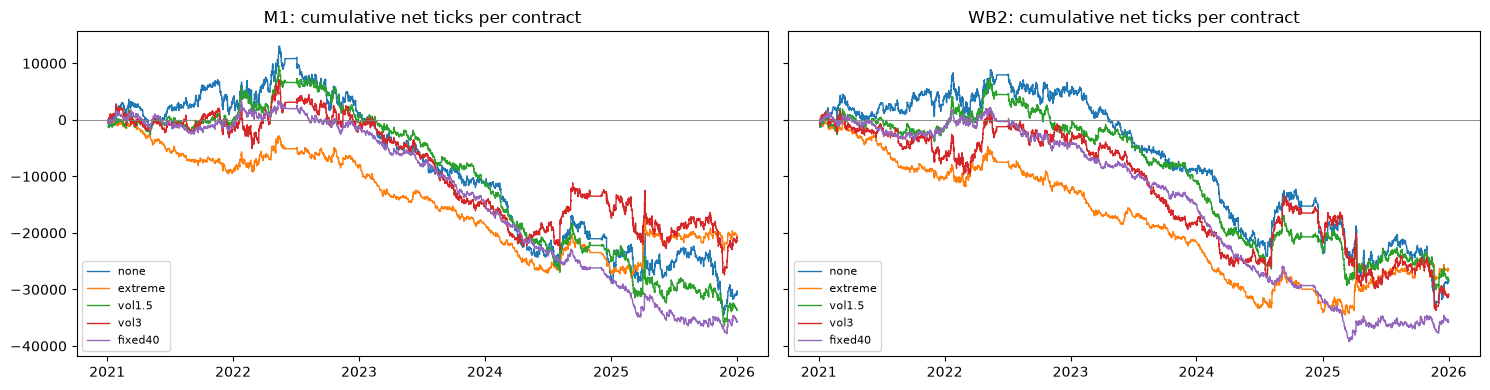

--- M1, no stop: net ticks by |burst move| quartile and by side


mean       count      
side                 -1     1    -1     1
burst_move_ticks                         
(0.999, 53.0]     -6.32 -4.89   655   955
(53.0, 86.0]     -11.15 -5.57   627   996
(86.0, 143.0]    -11.64  1.53   569   991
(143.0, 2776.0]   -3.83 -2.00   554  1041

--- WB2, no stop: net ticks by |burst move| quartile and by side


mean        count      
side                -1      1    -1     1
burst_move_ticks                         
(0.999, 54.0]    -6.83  -3.18   723  1073
(54.0, 86.0]     -3.35  -8.28   654  1050
(86.0, 144.0]    -5.80   7.46   619  1099
(144.0, 2776.0]   3.20 -14.15   615  1124

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for i, name in enumerate(("M1", "WB2")):
    for kind in BC.stops:
        tr = TR[(name, kind)]
        if len(tr):
            ax[i].plot(pd.to_datetime(tr["entry_ts"]), tr["net_ticks"].cumsum(), lw=1, label=kind)
    ax[i].axhline(0, color="grey", lw=0.6); ax[i].set_title(f"{name}: cumulative net ticks per contract"); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "equity.png", dpi=110); plt.show()
# descriptive: net by burst size and by direction (time-stop-only rule)
for name in ("M1", "WB2"):
    tr = TR[(name, "none")]
    if len(tr) > 20:
        q = pd.qcut(tr["burst_move_ticks"].abs(), 4, duplicates="drop")
        print(f"--- {name}, no stop: net ticks by |burst move| quartile and by side")
        display(tr.groupby([q, "side"], observed=True)["net_ticks"].agg(["mean", "count"]).round(2).unstack())

## 3. Verdict

In [7]:
passed = [f"{m}/{s}" for (m, s) in G.index[G["pass"]]]
verdict = ("CANDIDATE (2026 pre-registration): " + ", ".join(passed)) if passed else "NO_EDGE"
print(verdict)
summary = {"study": "RSW 04b (extension)" if FULL else "RSW 04", "engine": B.BR_VERSION,
           "window": [str(REFITS[0]), str(END)], "synthetic": SYNTHETIC, "synthetic_null": SYNTH_NULL,
           "round_trip_ticks": BC.round_trip_ticks, "fits": info,
           "episodes": {k: int(len(v)) for k, v in EV.items()},
           "results": json.loads(G.reset_index().to_json(orient="records")), "verdict": verdict,
           **({"by_window": json.loads(GW.to_json(orient="records"))} if FULL else {})}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

NO_EDGE
written 04b\summary.json
